In [2]:
import pandas as pd 
import numpy as np 
import scanpy as sc

In [3]:
frag_df = pd.read_csv('/home/rsun@ZHANGroup.local/sly_data/atac_fragments.tsv', sep = '\t',skiprows=52, header = None)
frag_df

,0,1,2,3,4
0,chr1,3000091,3000290,GGTGCTTCAAGCTTTG-1,1
1,chr1,3000401,3000574,CAGGGTGAGTGAGGGT-1,1
2,chr1,3000444,3000613,TCAAGTATCGTGCTTC-1,2
3,chr1,3000650,3000755,GAACGAATCACTTCAT-1,2
4,chr1,3000821,3001016,CCGCAAATCGCAATCG-1,1
...,...,...,...,...,...
143269471,JH584295.1,1927,1976,GCCGTGAGTTGGTGAC-1,1
143269472,JH584295.1,1927,1976,GTAAGGTCATAAGTCT-1,1
143269473,JH584295.1,1941,1976,GATTGGCGTAACGAGG-1,2
143269474,JH584295.1,1950,1976,GGTATGTTCAGCCAAT-1,1


In [6]:
scdata = sc.read_h5ad('/home/rsun@ZHANGroup.local/sly_data/grn_momics/data/filter/m_atac.h5ad')
atac_idx = scdata.obs.index.values 
for i,ele in enumerate(atac_idx):
    tmp = ele.split('-')[1:]
    atac_idx[i] = '-'.join(tmp)

In [7]:
sel_id = frag_df.iloc[:,3].isin(atac_idx)
print(sel_id.sum())

62482059


In [53]:
#frag_df = frag_df.loc[sel_id,:]
#frag_df.to_csv('filter_mhm_1_atac_fragment.tsv', index = False, sep = '\t')

## pycisTopic try

In [3]:
import pycisTopic
pycisTopic.__version__

import os
out_dir = "cisTopic_outs"
os.makedirs(out_dir, exist_ok = True)

/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/pycisTopic/__init__.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


In [4]:
multi_data = sc.read_h5ad('/home/rsun@ZHANGroup.local/sly_data/grn_momics/multi_rna_raw.h5ad')
scdata = sc.read_h5ad('/home/rsun@ZHANGroup.local/sly_data/grn_momics/data/filter/m_atac.h5ad')
mutual_idx = np.intersect1d(multi_data.obs.index.values, scdata.obs.index.values)
print(len(mutual_idx))

scdata = scdata[mutual_idx,:]
multi_data = multi_data[mutual_idx,:]
scdata.obs = multi_data.obs.copy()

atac_idx = scdata.obs.index.values
for i,ele in enumerate(atac_idx):
    tmp = ele.split('-')[1:]
    atac_idx[i] = '-'.join(tmp)
scdata.obs.index = atac_idx

2409


### Getting pseudobulk profiles from cell annotations

In [5]:
chromsizes = pd.read_table(
    "http://hgdownload.cse.ucsc.edu/goldenPath/mm10/bigZips/mm10.chrom.sizes",
    header = None,
    names = ["Chromosome", "End"]
)

chromsizes.insert(1, "Start", 0)
chromsizes.head()

,Chromosome,Start,End
0,chr1,0,195471971
1,chr2,0,182113224
2,chrX,0,171031299
3,chr3,0,160039680
4,chr4,0,156508116


In [6]:
fragments_dict = {'M': '/home/rsun@ZHANGroup.local/sly_data/grn_momics/filter_mhm_1_atac_fragment.tsv.gz'}
#'/home/rsun@ZHANGroup.local/sly_data/grn_momics/filter_mhm_1_atac_fragment.tsv.gz'}
cell_data = scdata.obs.copy()

In [7]:
cell_data

,leiden,eco,species
AAACAGCCAAGTCGCT-1,3,non-eco,M
AAACAGCCACTAAATC-1,5,non-eco,M
AAACAGCCATCAGCAC-1,5,non-eco,M
AAACATGCAGGTTACC-1,1,non-eco,M
AAACCAACATCCAGGT-1,3,non-eco,M
...,...,...,...
TTTGTCTAGGGTCCAC-1,7,non-eco,M
TTTGTGAAGGCCATCA-1,3,non-eco,M
TTTGTGGCACCCACAG-1,3,non-eco,M
TTTGTGGCACCTGTAA-1,5,non-eco,M


In [38]:
from pycisTopic.pseudobulk_peak_calling import export_pseudobulk
os.makedirs(os.path.join(out_dir, "consensus_peak_calling"), exist_ok = True)
os.makedirs(os.path.join(out_dir, "consensus_peak_calling/pseudobulk_bed_files"), exist_ok = True)
os.makedirs(os.path.join(out_dir, "consensus_peak_calling/pseudobulk_bw_files"), exist_ok = True)


bw_paths, bed_paths = export_pseudobulk(
    input_data = cell_data,
    variable = "leiden",
    sample_id_col = "species",
    chromsizes = chromsizes,
    bed_path = os.path.join(out_dir, "consensus_peak_calling/pseudobulk_bed_files"),
    bigwig_path = os.path.join(out_dir, "consensus_peak_calling/pseudobulk_bw_files"),
    path_to_fragments = fragments_dict,
    n_cpu = 10,
    normalize_bigwig = True,
    temp_dir = "/tmp",
    split_pattern = "-"
)

2025-06-10 07:09:48,278 cisTopic     INFO     Splitting fragments by cell type.
2025-06-10 07:10:31,488 cisTopic     INFO     generating bigwig files


/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/pycisTopic/__init__.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/pycisTopic/__init__.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/pycisTopic/__init__.py:3: UserWarning: pkg_resources is deprecated as an API. See ht

In [39]:
with open(os.path.join(out_dir, "consensus_peak_calling/bw_paths.tsv"), "wt") as f:
    for v in bw_paths:
        _ = f.write(f"{v}\t{bw_paths[v]}\n")

with open(os.path.join(out_dir, "consensus_peak_calling/bed_paths.tsv"), "wt") as f:
    for v in bed_paths:
        _ = f.write(f"{v}\t{bed_paths[v]}\n")

### infer consensus peaks using macs

In [9]:
bw_paths = {}
with open(os.path.join(out_dir, "consensus_peak_calling/bw_paths.tsv")) as f:
    for line in f:
        v, p = line.strip().split("\t")
        bw_paths.update({v: p})

bed_paths = {}
with open(os.path.join(out_dir, "consensus_peak_calling/bed_paths.tsv")) as f:
    for line in f:
        v, p = line.strip().split("\t")
        bed_paths.update({v: p})

from pycisTopic.pseudobulk_peak_calling import peak_calling
macs_path = "/home/rsun@ZHANGroup.local/anaconda3/envs/pyscenic/bin/macs2"

os.makedirs(os.path.join(out_dir, "consensus_peak_calling/MACS"), exist_ok = True)

narrow_peak_dict = peak_calling(
    macs_path = macs_path,
    bed_paths = bed_paths,
    outdir = os.path.join(os.path.join(out_dir, "consensus_peak_calling/MACS")),
    genome_size = 'hs',
    n_cpu = 10,
    input_format = 'BEDPE',
    shift = 73,
    ext_size = 146,
    keep_dup = 'all',
    q_value = 0.05,
    _temp_dir = None
)

2025-06-10 07:58:14,565	INFO worker.py:1724 -- Started a local Ray instance.
(pid=2057740) /home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/pycisTopic/__init__.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
(pid=2057740)   from pkg_resources import DistributionNotFound, get_distribution


(macs_call_peak_ray pid=2057744) 2025-06-10 07:58:16,278 cisTopic     INFO     Calling peaks for 10 with /home/rsun@ZHANGroup.local/anaconda3/envs/pyscenic/bin/macs2 callpeak --treatment cisTopic_outs/consensus_peak_calling/pseudobulk_bed_files/10.fragments.tsv.gz --name 10  --outdir cisTopic_outs/consensus_peak_calling/MACS --format BEDPE --gsize hs --qvalue 0.05 --nomodel --shift 73 --extsize 146 --keep-dup all --call-summits --nolambda
(macs_call_peak_ray pid=2057738) 2025-06-10 07:58:17,168 cisTopic     INFO     0 done!
(macs_call_peak_ray pid=2057738) 2025-06-10 07:58:17,690 cisTopic     INFO     6 done!
(macs_call_peak_ray pid=2057738) 2025-06-10 07:58:17,179 cisTopic     INFO     Calling peaks for 6 with /home/rsun@ZHANGroup.local/anaconda3/envs/pyscenic/bin/macs2 callpeak --treatment cisTopic_outs/consensus_peak_calling/pseudobulk_bed_files/6.fragments.tsv.gz --name 6  --outdir cisTopic_outs/consensus_peak_calling/MACS --format BEDPE --gsize hs --qvalue 0.05 --nomodel --shift 7

(pid=2057739) /home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/pycisTopic/__init__.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81. [repeated 9x across cluster]
(pid=2057739)   from pkg_resources import DistributionNotFound, get_distribution [repeated 9x across cluster]


In [11]:
from pycisTopic.iterative_peak_calling import get_consensus_peaks
# Other param
peak_half_width=250
path_to_blacklist="/home/rsun@ZHANGroup.local/projects_list/pycisTopic-main/blacklist/mm10-blacklist.v2.bed"
# Get consensus peaks
consensus_peaks = get_consensus_peaks(
    narrow_peaks_dict = narrow_peak_dict,
    peak_half_width = peak_half_width,
    chromsizes = chromsizes,
    path_to_blacklist = path_to_blacklist)

2025-06-10 08:02:31,007 cisTopic     INFO     Extending and merging peaks per class
2025-06-10 08:03:23,191 cisTopic     INFO     Normalizing peak scores
2025-06-10 08:03:23,630 cisTopic     INFO     Merging peaks
Warning! Start and End columns now have different dtypes: int64 and int32
2025-06-10 08:04:38,955 cisTopic     INFO     Done!


In [12]:
consensus_peaks.to_bed(
    path = os.path.join(out_dir, "consensus_peak_calling/consensus_regions.bed"),
    keep =True,
    compression = 'infer',
    chain = False)

/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/pyranges/out.py:37: FutureWarning: Passing a set as an indexer is deprecated and will raise in a future version. Use a list instead.
  return pd.concat([outdf, df.get(noncanonical)], axis=1)
/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/pyranges/out.py:37: FutureWarning: Passing a set as an indexer is deprecated and will raise in a future version. Use a list instead.
  return pd.concat([outdf, df.get(noncanonical)], axis=1)
/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/pyranges/out.py:37: FutureWarning: Passing a set as an indexer is deprecated and will raise in a future version. Use a list instead.
  return pd.concat([outdf, df.get(noncanonical)], axis=1)
/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/pyranges/out.py:37: FutureWarning: Passing a set as an indexer is deprecated and will raise in a fu

### QC

In [13]:
!pycistopic tss gene_annotation_list | grep Mouse

/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/pycisTopic/__init__.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
mmurinus_gene_ensembl	Mouse Lemur genes (Mmur_3.0)
mmusculus_gene_ensembl	Mouse genes (GRCm39)


In [14]:
!mkdir -p outs/qc
!pycistopic tss get_tss \
    --output outs/qc/tss.bed \
    --name "mmusculus_gene_ensembl" \
    --to-chrom-source ucsc \
    --ucsc mm10

/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/pycisTopic/__init__.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
- Get TSS annotation from Ensembl BioMart with the following settings:
  - biomart_name: "mmusculus_gene_ensembl"
  - biomart_host: "http://www.ensembl.org"
  - transcript_type: ['protein_coding']
  - use_cache: True
- Getting chromosome sizes and alias mapping for "mm10" from UCSC.
- Update chromosome names in TSS annotation to "ucsc" chromosome names.
- Writing TSS annotation BED file to "outs/qc/tss.bed".


In [15]:
!head outs/qc/tss.bed | column -t

#     Chromosome  Start  End      Gene  Score  Strand          Transcript_type
chrM  2750        2751   mt-Nd1   .     +      protein_coding  
chrM  3913        3914   mt-Nd2   .     +      protein_coding  
chrM  5327        5328   mt-Co1   .     +      protein_coding  
chrM  7012        7013   mt-Co2   .     +      protein_coding  
chrM  7765        7766   mt-Atp8  .     +      protein_coding  
chrM  7926        7927   mt-Atp6  .     +      protein_coding  
chrM  8606        8607   mt-Co3   .     +      protein_coding  
chrM  9458        9459   mt-Nd3   .     +      protein_coding  
chrM  9876        9877   mt-Nd4l  .     +      protein_coding  


In [19]:
!pycistopic qc \
    --fragments /home/rsun@ZHANGroup.local/sly_data/grn_momics/filter_mhm_1_atac_fragment.tsv.gz \
    --regions cisTopic_outs/consensus_peak_calling/consensus_regions.bed \
    --tss outs/qc/tss.bed \
    --output outs/qc/mhm_qc

/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/pycisTopic/__init__.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


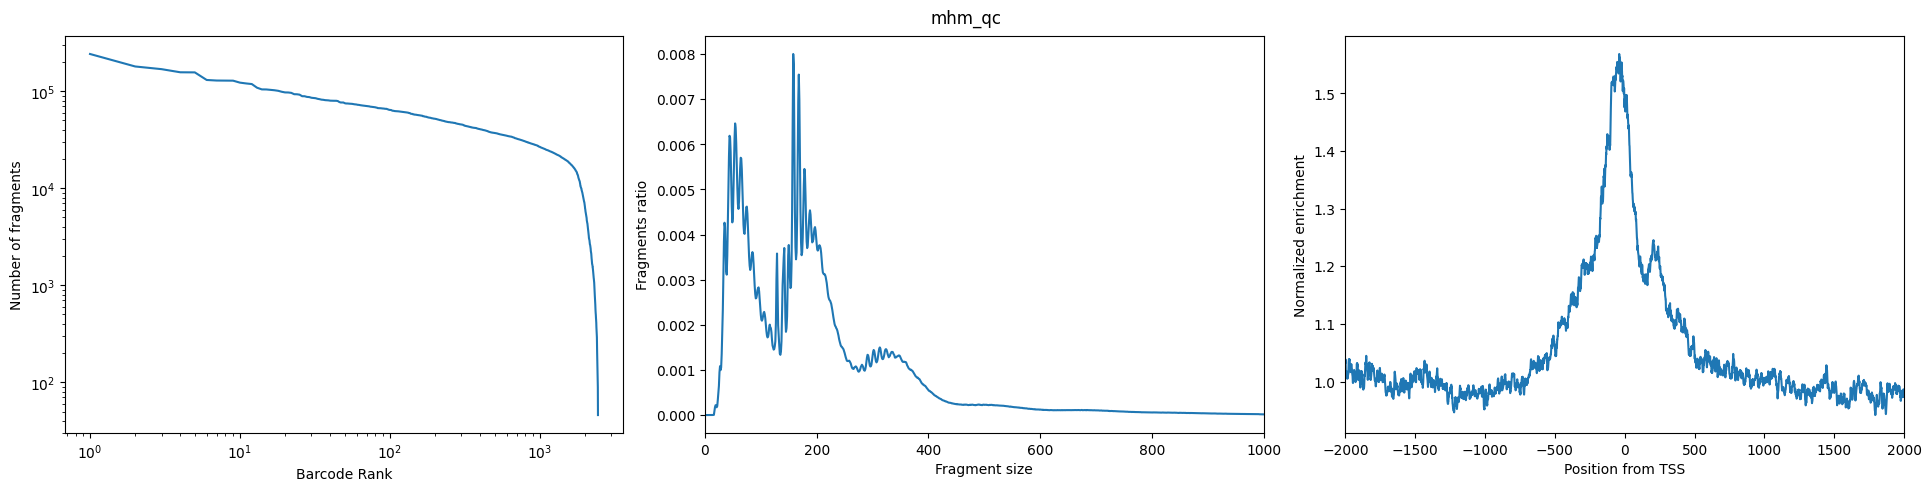

In [24]:
from pycisTopic.plotting.qc_plot import plot_sample_stats, plot_barcode_stats
import matplotlib.pyplot as plt

for sample_id in fragments_dict:
    fig = plot_sample_stats(
        sample_id = 'mhm_qc',
        pycistopic_qc_output_dir = "outs/qc"
    )

In [25]:
from pycisTopic.qc import get_barcodes_passing_qc_for_sample
sample_id_to_barcodes_passing_filters = {}
sample_id_to_thresholds = {}
for sample_id in fragments_dict:
    sample_id = 'mhm_qc'
    (
        sample_id_to_barcodes_passing_filters[sample_id],
        sample_id_to_thresholds[sample_id]
    ) = get_barcodes_passing_qc_for_sample(
            sample_id = sample_id,
            pycistopic_qc_output_dir = "outs/qc",
            unique_fragments_threshold = None, # use automatic thresholding
            tss_enrichment_threshold = None, # use automatic thresholding
            frip_threshold = 0,
            use_automatic_thresholds = True,
    )

mhm_qc:
	Using automatic threshold for unique fragments: 3909.2616610957098
	Using automatic threshold for TSS enrichment: 1.5338544554455447


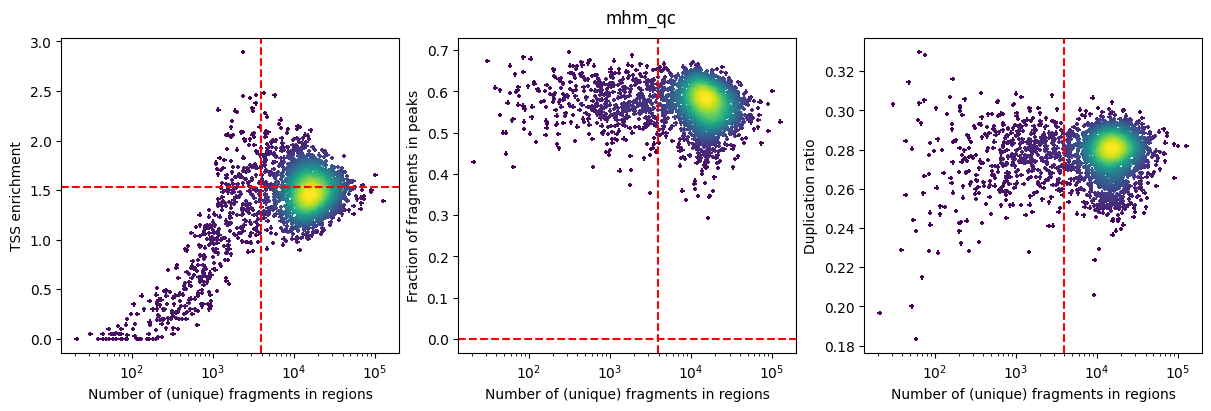

In [26]:
for sample_id in fragments_dict:
    sample_id = 'mhm_qc'
    fig = plot_barcode_stats(
        sample_id = sample_id,
        pycistopic_qc_output_dir = "outs/qc",
        bc_passing_filters = sample_id_to_barcodes_passing_filters[sample_id],
        detailed_title = False,
        **sample_id_to_thresholds[sample_id]
    )

### create cisTopic object

In [28]:
path_to_regions = os.path.join(out_dir, "consensus_peak_calling/consensus_regions.bed")
#path_to_blacklist = "pycisTopic/blacklist/hg38-blacklist.v2.bed"
pycistopic_qc_output_dir = "outs/qc"

from pycisTopic.cistopic_class import create_cistopic_object_from_fragments
import polars as pl

cistopic_obj_list = []
for sample_id in fragments_dict:
    sample_id = 'mhm_qc'
    sample_metrics = pl.read_parquet(
        os.path.join(pycistopic_qc_output_dir, f'{sample_id}.fragments_stats_per_cb.parquet')
    ).to_pandas().set_index("CB").loc[ sample_id_to_barcodes_passing_filters[sample_id] ]
    cistopic_obj = create_cistopic_object_from_fragments(
        path_to_fragments = fragments_dict['M'],
        path_to_regions = path_to_regions,
        path_to_blacklist = path_to_blacklist,
        metrics = sample_metrics,
        valid_bc = sample_id_to_barcodes_passing_filters[sample_id],
        n_cpu = 1,
        project = sample_id,
        split_pattern = '-'
    )
    cistopic_obj_list.append(cistopic_obj)

2025-06-10 08:14:46,720 cisTopic     INFO     Reading data for mhm_qc


2025-06-10 08:15:24,891 cisTopic     INFO     metrics provided!
2025-06-10 08:15:26,372 cisTopic     INFO     Counting fragments in regions
2025-06-10 08:15:34,366 cisTopic     INFO     Creating fragment matrix
2025-06-10 08:15:42,532 cisTopic     INFO     Converting fragment matrix to sparse matrix
2025-06-10 08:15:44,314 cisTopic     INFO     Removing blacklisted regions
2025-06-10 08:15:45,322 cisTopic     INFO     Creating CistopicObject
2025-06-10 08:15:45,899 cisTopic     INFO     Done!


In [29]:
cistopic_obj = cistopic_obj_list[0]
print(cistopic_obj)
import pickle
pickle.dump(
    cistopic_obj,
    open(os.path.join(out_dir, "cistopic_obj.pkl"), "wb")
)

CistopicObject from project mhm_qc with n_cells × n_regions = 797 × 421239


### add metadata to cistopic

In [30]:
import pandas as pd
#cell_data = pd.read_table("data/cell_data.tsv", index_col = 0)
#cell_data.head()
cistopic_obj.add_cell_data(cell_data, split_pattern='-')
pickle.dump(
    cistopic_obj,
    open(os.path.join(out_dir, "cistopic_obj.pkl"), "wb")
)

In [31]:
cistopic_obj.cell_data

,cisTopic_nr_frag,cisTopic_log_nr_frag,cisTopic_nr_acc,cisTopic_log_nr_acc,sample_id,barcode_rank,total_fragments_count,log10_total_fragments_count,unique_fragments_count,log10_unique_fragments_count,...,duplication_ratio,nucleosome_signal,tss_enrichment,pdf_values_for_tss_enrichment,pdf_values_for_fraction_of_fragments_in_peaks,pdf_values_for_duplication_ratio,barcode,leiden,eco,species
TGTTGTTTCTTGATGA-1-mhm_qc,15269,4.183811,14125,4.149988,mhm_qc,1131,34463,4.537366,24608,4.391094,...,0.285959,1.252033,1.670188,1.506692,10.547870,42.801442,TGTTGTTTCTTGATGA-1,5,non-eco,M
CAATATGTCATTGTCT-1-mhm_qc,15124,4.179667,14023,4.146841,mhm_qc,1153,32668,4.514136,24266,4.385016,...,0.257194,1.390006,1.721115,1.197438,10.399985,9.633351,CAATATGTCATTGTCT-1,5,non-eco,M
GTCATGCCAATTGAGA-1-mhm_qc,16640,4.221153,15180,4.181272,mhm_qc,917,39649,4.598243,28199,4.450249,...,0.288784,1.105040,1.590064,2.045085,9.698369,32.037341,GTCATGCCAATTGAGA-1,3,non-eco,M
CCTATATTCACGTTAA-1-mhm_qc,15055,4.177681,13995,4.145973,mhm_qc,1016,36176,4.558433,26287,4.419758,...,0.273358,0.913969,1.546546,2.207545,8.337087,36.897962,CCTATATTCACGTTAA-1,3,non-eco,M
TCATGTTTCTCGCCTG-1-mhm_qc,16924,4.228503,15368,4.186617,mhm_qc,816,42374,4.627110,29913,4.475874,...,0.294072,0.766201,1.550074,2.257861,8.093067,13.322058,TCATGTTTCTCGCCTG-1,3,non-eco,M
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
GGAACGGTCAAGCGCC-1-mhm_qc,4461,3.649432,4292,3.63266,mhm_qc,1998,8991,3.953856,6557,3.816771,...,0.270715,1.042302,2.478133,0.022604,0.616069,5.977403,GGAACGGTCAAGCGCC-1,5,non-eco,M
ATCGCCCGTTAGGATT-1-mhm_qc,5938,3.77364,5742,3.759063,mhm_qc,1891,13802,4.139973,9992,3.999696,...,0.276047,1.215925,1.546176,0.462540,2.830574,11.871291,ATCGCCCGTTAGGATT-1,3,non-eco,M
GCTAACAGTTCCGGGA-1-mhm_qc,4710,3.673021,4546,3.657629,mhm_qc,1943,11342,4.054728,8236,3.915769,...,0.273849,0.790436,1.867276,0.181216,1.700509,7.583620,GCTAACAGTTCCGGGA-1,4,non-eco,M
TGGTCATAGGCTAAGA-1-mhm_qc,7376,3.867821,7055,3.848497,mhm_qc,1824,16851,4.226651,12375,4.092580,...,0.265622,1.060180,2.021979,0.121136,4.079522,8.420740,TGGTCATAGGCTAAGA-1,3,non-eco,M


### LDA model

In [33]:
os.makedirs('lda_test', exist_ok=True)
os.environ['MALLET_MEMORY'] = '200G'
from pycisTopic.lda_models import run_cgs_models_mallet
# Configure path Mallet
mallet_path="/home/rsun@ZHANGroup.local/projects_list/Mallet-202108/bin/mallet"
# Run models
models=run_cgs_models_mallet(
    cistopic_obj,
    n_topics=[2, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50],
    n_cpu=64,
    n_iter=500,
    random_state=555,
    alpha=50,
    alpha_by_topic=True,
    eta=0.1,
    eta_by_topic=False,
    tmp_path="lda_test",
    save_path="lda_test",
    mallet_path=mallet_path,
)

2025-06-10 08:21:27,343 cisTopic     INFO     Formatting input to corpus
2025-06-10 08:21:27,456 cisTopic     INFO     Running model with 2 topics
2025-06-10 08:21:27,457 LDAMalletWrapper INFO     Serializing temporary corpus to lda_test/corpus.txt
2025-06-10 08:21:30,709 LDAMalletWrapper INFO     Converting temporary corpus to MALLET format with: /home/rsun@ZHANGroup.local/projects_list/Mallet-202108/bin/mallet import-file --preserve-case --keep-sequence --token-regex \S+ --input lda_test/corpus.txt --output lda_test/corpus.mallet
2025-06-10 08:21:38,254 LDAMalletWrapper INFO     Training MALLET LDA with: /home/rsun@ZHANGroup.local/projects_list/Mallet-202108/bin/mallet train-topics --input lda_test/corpus.mallet --num-topics 2 --alpha 50 --beta 0.1 --optimize-interval 0 --num-threads 64 --output-state lda_test/da49b8_state.mallet.gz --output-doc-topics lda_test/da49b8_doctopics.txt --output-topic-keys lda_test/da49b8_topickeys.txt --num-iterations 500 --inferencer-filename lda_test/d

In [34]:
pickle.dump(
    models,
    open(os.path.join(out_dir, "models.pkl"), "wb")
)

### Model selection

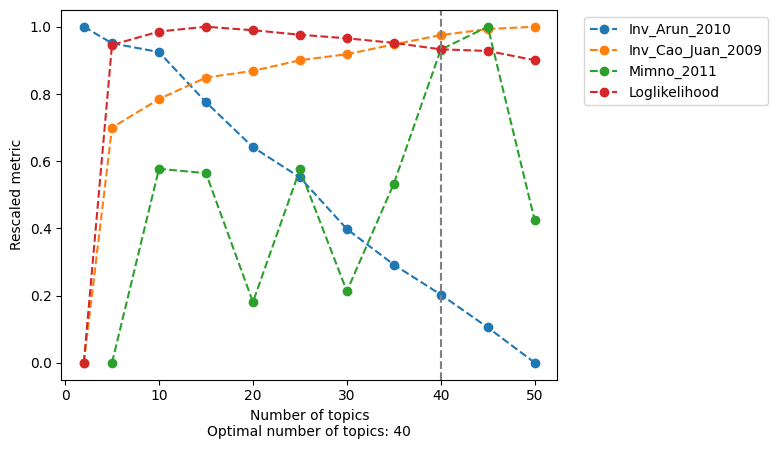

In [35]:
from pycisTopic.lda_models import evaluate_models
model = evaluate_models(
    models,
    select_model = 40,
    return_model = True
)

In [36]:
cistopic_obj.add_LDA_model(model)
pickle.dump(
    cistopic_obj,
    open(os.path.join(out_dir, "cistopic_obj.pkl"), "wb")
)

### clusster and visualize

In [37]:
from pycisTopic.clust_vis import (
    find_clusters,
    run_umap,
    run_tsne,
    plot_metadata,
    plot_topic,
    cell_topic_heatmap
)

In [38]:
find_clusters(
    cistopic_obj,
    target  = 'cell',
    k = 10,
    res = [0.6, 1.2, 3],
    prefix = 'pycisTopic_',
    scale = True,
    split_pattern = '-'
)

2025-06-10 09:03:01,417 cisTopic     INFO     Finding neighbours


In [41]:
cistopic_obj

In [ ]:
run_umap(
    cistopic_obj,
    target  = 'cell', scale=True)

plot_metadata(
    cistopic_obj,
    reduction_name='UMAP',
    variables=['leiden'],
    target='cell',
    text_size=10,
    dot_size=5)

In [52]:
tmp = []
for ele in scdata.obs.leiden.values.astype(object):
    if ele not in tmp:
        tmp.append(ele)
print(len(tmp))

11


AnnData object with n_obs × n_vars = 2419 × 142746
    obs: 'leiden', 'eco', 'species'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'm_peaks'
    uns: 'atac'